# 05 — Partie C : réseaux de neurones sur embeddings

### C.1 Du texte aux nombres : tokens, vocabulaire, OOV
1. **Tokeniser** : couper le texte en mots et ponctuation, en minuscules. On garde les mots vides. Les contractions sont coupées comme dans GloVe (`don't` → `do` + `n't`) : la négation reste un token.
2. **Vocabulaire** : les mots présents au moins 2 fois dans le **train**, chacun avec un numéro.
3. **Encoder** : remplacer chaque mot par son numéro ; un mot inconnu devient `<unk>`.

Entrée imposée : conclusion, position et prémisse, séparées par `<sep>`.

In [1]:
import pandas as pd
from collections import Counter
from valeval.data import load_split, VALUES
from valeval.preprocess import UNK, SEP, Vocabulaire, corpus, tokens_argument

SPLITS = {"train": "training", "val": "validation", "test": "test"}
d = {nom: load_split(f) for nom, f in SPLITS.items()}
toks = {nom: corpus(df) for nom, df in d.items()}
vocab = Vocabulaire(toks["train"], min_freq=2)
print("mots distincts du train :", len(vocab.freq))
print("vocabulaire (fréquence ≥ 2 + 3 spéciaux) :", len(vocab))

mots distincts du train : 7868
vocabulaire (fréquence ≥ 2 + 3 spéciaux) : 4582


In [2]:
exemple = toks["train"][1]
print(exemple)
print(vocab.encoder(exemple, 128))

['we', 'should', 'ban', 'fast', 'food', '<sep>', 'in', 'favor', 'of', '<sep>', 'fast', 'food', 'should', 'be', 'banned', 'because', 'it', 'is', 'really', 'bad', 'for', 'your', 'health', 'and', 'is', 'costly', '.']
[4458, 3724, 408, 1651, 1733, 2, 2129, 1658, 2822, 2, 1651, 1733, 3724, 427, 414, 432, 2317, 2311, 3353, 401, 1735, 4575, 1967, 254, 2311, 955, 11]


### Taux d'OOV (*out-of-vocabulary*)
Part des mots de val et test absents du vocabulaire. Deux façons de compter :
- **par occurrence** : chaque apparition compte ; c'est ce que le modèle subit en lisant ;
- **par mot distinct** : chaque mot compte une fois.

In [3]:
lignes = []
for nom, textes in toks.items():
    tous = [t for texte in textes for t in texte if t != SEP]
    inconnus = [t for t in tous if t not in vocab.indice]
    distincts = set(tous)
    lignes.append({"split": nom, "occurrences": len(tous), "OOV par occurrence (%)": 100 * len(inconnus) / len(tous),
                   "mots distincts": len(distincts),
                   "OOV par mot distinct (%)": 100 * len(distincts - set(vocab.indice)) / len(distincts)})
pd.DataFrame(lignes).round(2)

,split,occurrences,OOV par occurrence (%),mots distincts,OOV par mot distinct (%)
0,train,172325,1.91,7868,41.80
1,val,61651,9.04,4799,40.09
2,test,49678,10.04,4224,37.74


In [4]:
inconnus_val = Counter(t for texte in toks["val"] for t in texte if t not in vocab.indice)
print("Mots inconnus les plus fréquents dans val :", inconnus_val.most_common(20))

Mots inconnus les plus fréquents dans val : [('blockade', 212), ('surrogacy', 204), ('gaza', 187), ('vocational', 185), ('payday', 176), ('holocaust', 176), ('strip', 167), ('celibacy', 166), ('entrapment', 164), ('defenders', 161), ('homeopathy', 157), ('vow', 156), ('assisted', 151), ('denial', 149), ('iq', 32), ('israel', 28), ('homeopathic', 22), ('surrogate', 19), ('hamas', 18), ('hindi', 17)]


In [5]:
longueurs = pd.Series([len(t) for t in toks["train"]])
print(longueurs.describe(percentiles=[.5, .95, .99]).round(1).to_string())
print("arguments du train coupés à 100 tokens :", int((longueurs > 100).sum()))

count    5393.0
mean       34.0
std        16.5
min        11.0
50%        30.0
95%        66.0
99%       105.0
max       160.0
arguments du train coupés à 100 tokens : 65


### C.2 Embeddings : donner un sens aux numéros
Un **embedding** représente un mot par un vecteur de nombres (ici 300), appris de sorte que des mots employés dans des contextes semblables aient des vecteurs proches.
**GloVe** (glove.6B.300d) : 400 000 mots, appris sur ~6 milliards de mots de texte.

Proximité entre deux mots = **similarité cosinus**, de -1 à 1 (1 = même direction).

In [6]:
import numpy as np
from valeval.embeddings import charger_glove, voisins

g_mots, g_mat = charger_glove()
g_idx = {m: i for i, m in enumerate(g_mots)}
print(g_mat.shape)
print("vecteur de 'freedom', 8 premiers nombres :", g_mat[g_idx["freedom"]][:8].round(3))

(400001, 300)
vecteur de 'freedom', 8 premiers nombres : [-0.129 -0.878 -0.205 -0.226 -0.476 -0.196  0.281  0.515]


**Mots proches :** les voisins ont du sens, sans qu'aucune définition ait été donnée.

In [7]:
pd.DataFrame({m: [f"{w} ({c})" for w, c in voisins(g_mat[g_idx[m]], g_mots, g_mat, exclure={m})]
              for m in ["freedom", "tradition", "health", "surrogacy", "pleasure"]})

,freedom,tradition,health,surrogacy,pleasure
0,freedoms (0.66),traditions (0.84),care (0.76),altruistic (0.44),enjoyment (0.64)
1,liberty (0.64),traditional (0.67),healthcare (0.66),insemination (0.43),delight (0.55)
2,democracy (0.61),culture (0.55),education (0.64),adoptions (0.39),pleasures (0.55)
3,rights (0.61),steeped (0.53),medical (0.64),ivf (0.39),thrill (0.52)
4,liberties (0.57),ancient (0.52),hospitals (0.56),transracial (0.37),enjoy (0.5)
5,equality (0.54),ritual (0.52),welfare (0.55),matchmaking (0.36),fun (0.49)


**Analogies :** les différences entre vecteurs portent aussi du sens : `king - man + woman` tombe près de `queen`.

In [8]:
def analogie(a, b, c):
    v = g_mat[g_idx[a]] - g_mat[g_idx[b]] + g_mat[g_idx[c]]
    return voisins(v, g_mots, g_mat, n=3, exclure={a, b, c})

for a, b, c in [("king", "man", "woman"), ("paris", "france", "morocco"), ("freedom", "good", "bad")]:
    print(f"{a} - {b} + {c} =", analogie(a, b, c))

king - man + woman = [('queen', 0.69), ('monarch', 0.56), ('throne', 0.56)]


paris - france + morocco = [('rabat', 0.59), ('cairo', 0.58), ('casablanca', 0.56)]


freedom - good + bad = [('liberty', 0.5), ('freedoms', 0.48), ('rights', 0.48)]


### GloVe connaît-il les mots inconnus de notre vocabulaire ?

In [9]:
couverts = sum(m in g_idx for m in vocab.mots[3:])
print(f"vocabulaire du train couvert par GloVe : {couverts} / {len(vocab) - 3} ({100 * couverts / (len(vocab) - 3):.1f} %)")
print("non couverts :", [m for m in vocab.mots[3:] if m not in g_idx][:15])

lignes = []
for nom, textes in toks.items():
    tous = [t for texte in textes for t in texte if t != SEP]
    sans = sum(t not in vocab.indice for t in tous)
    avec = sum(t not in vocab.indice and t not in g_idx for t in tous)
    lignes.append({"split": nom, "OOV vocabulaire train (%)": 100 * sans / len(tous),
                   "OOV si on ajoute GloVe (%)": 100 * avec / len(tous)})
pd.DataFrame(lignes).round(2)

vocabulaire du train couvert par GloVe : 4560 / 4579 (99.6 %)
non couverts : ['aadhaar', 'brexit', 'cbam', 'covid', 'cryptocurrencies', 'deterant', 'deterent', 'deterrant', 'haling', 'indoctrinates', 'intensivists', 'memberstaates', 'persue', 'remigration', 'seperation']


,split,OOV vocabulaire train (%),OOV si on ajoute GloVe (%)
0,train,1.91,0.11
1,val,9.04,0.12
2,test,10.04,0.19


In [10]:
print({m: m in g_idx for m in ["blockade", "surrogacy", "gaza", "payday", "celibacy", "homeopathy"]})
restants = Counter(t for texte in toks["val"] for t in texte if t not in vocab.indice and t not in g_idx)
print("Encore inconnus dans val :", restants.most_common(10))

{'blockade': True, 'surrogacy': True, 'gaza': True, 'payday': True, 'celibacy': True, 'homeopathy': True}
Encore inconnus dans val : [('zbnf', 6), ('pushbacks', 4), ('micromobility', 3), ('fomo', 2), ('sportrays', 2), ('trustable', 2), ('irrealistic', 2), ('birthparents', 1), ('amoint', 1), ('dessimination', 1)]


### C.3 Premier réseau : C1, BiLSTM
Entraînement dans `scripts/run_C.py` (modèle : `src/valeval/models.py`, boucle : `src/valeval/train.py`).
Réglages communs : hidden 128, dropout 0,3, AdamW lr 1e-3, batch 32, 30 époques max, arrêt après 5 époques sans progrès du macro-F1 val.
On compare : embeddings aléatoires ou GloVe (figés), résumé par dernier état ou par max-pooling.

In [11]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

RUNS = Path("../cache/runs")
noms = ["C1_aleatoire_dernier", "C1_aleatoire_max", "C1_glove_dernier", "C1_glove_max"]
runs = {n: json.loads((RUNS / f"{n}_seed42.json").read_text(encoding="utf-8")) for n in noms}
pd.DataFrame([{"modèle": n, "macro-F1 val": r["macro_f1"], "seuil": r["seuil"], "époques": len(r["courbes"]),
               "temps (s)": round(r["temps_s"]), "paramètres entraînés": r["params"]} for n, r in runs.items()]).round(3)

,modèle,macro-F1 val,seuil,époques,temps (s),paramètres entraînés
0,C1_aleatoire_dernier,0.290,0.05,17,59,1820060
1,C1_aleatoire_max,0.335,0.18,22,84,1820060
2,C1_glove_dernier,0.397,0.14,22,65,445460
3,C1_glove_max,0.420,0.22,21,71,445460


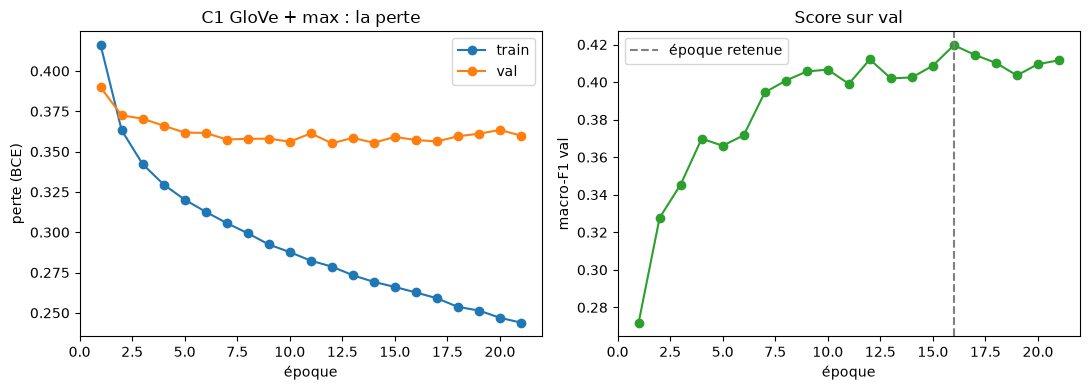

,epoque,perte_train,perte_val,macro_f1_val
0,1,0.416,0.390,0.272
1,2,0.363,0.372,0.328
2,3,0.342,0.370,0.345
3,4,0.330,0.366,0.370
4,5,0.320,0.362,0.366
5,6,0.313,0.362,0.372
6,7,0.306,0.358,0.394
7,8,0.299,0.358,0.401
8,9,0.292,0.358,0.406
9,10,0.288,0.356,0.407


In [12]:
c = pd.DataFrame(runs["C1_glove_max"]["courbes"])
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.plot(c.epoque, c.perte_train, marker="o", label="train")
a.plot(c.epoque, c.perte_val, marker="o", label="val")
a.set(xlabel="époque", ylabel="perte (BCE)", title="C1 GloVe + max : la perte"); a.legend()
b.plot(c.epoque, c.macro_f1_val, marker="o", color="tab:green")
b.axvline(c.epoque[c.macro_f1_val.idxmax()], color="gray", ls="--", label="époque retenue")
b.set(xlabel="époque", ylabel="macro-F1 val", title="Score sur val"); b.legend()
plt.tight_layout(); plt.savefig("../figures/C1_courbes.png", dpi=120); plt.show()
c.round(3)

**Lecture :**
- **GloVe est le facteur décisif :** 0,335 → 0,420 avec max-pooling, 0,290 → 0,397 avec le dernier état, et 4 fois moins de paramètres à entraîner.
- **Max-pooling > dernier état :** 0,420 contre 0,397 avec GloVe. Une valeur peut se révéler n'importe où dans l'argument, pas seulement à la fin.
- **Prudence sur 0,420 :** une seule graine, et l'époque comme le seuil sont choisis sur val. Le score oscille entre 0,40 et 0,42 d'une époque à l'autre : 0,420 est un pic. L'écart avec la baseline (0,394) et le NLI (0,407) reste à confirmer sur 3 graines.
- **Courbes :** la perte train baisse toujours alors que la perte val cesse de baisser vers l'époque 10 : c'est le début du surapprentissage.

### C.4 C2 : BiLSTM + attention (implémentée par nous)
Au lieu de garder le maximum (C1), on calcule pour chaque mot `i` un poids : `α_i = softmax(vᵀ tanh(W h_i))`, puis le résumé `c = Σ α_i h_i`.
Les poids sont positifs et leur somme vaut 1 : on peut donc **lire** où le modèle regarde.

**Où va l'attention ?** Part de l'attention sur chaque zone de l'argument, comparée à la part de tokens de cette zone.

In [13]:
from collections import defaultdict

attn = json.loads((RUNS / "C2_glove_seed42_attention.json").read_text(encoding="utf-8"))
r2 = json.loads((RUNS / "C2_glove_seed42.json").read_text(encoding="utf-8"))
print("C2 macro-F1 val :", round(r2["macro_f1"], 3), "| époques :", len(r2["courbes"]))

zones = defaultdict(lambda: [0.0, 0.0])
for a in attn:
    t, p = a["tokens"], np.array(a["alpha"])
    seps = [i for i, x in enumerate(t) if x == SEP]
    for nom, deb, fin in [("conclusion", 0, seps[0]), ("position", seps[0], seps[1] + 1), ("prémisse", seps[1] + 1, len(t))]:
        zones[nom][0] += p[deb:fin].sum() / len(attn)
        zones[nom][1] += (fin - deb) / len(t) / len(attn)
pd.DataFrame(zones, index=["part de l'attention", "part des tokens"]).T.round(3)

C2 macro-F1 val : 0.388 | époques : 14


,part de l'attention,part des tokens
conclusion,0.353,0.210
position,0.013,0.136
prémisse,0.634,0.655


**Quels mots attirent l'attention ?** Poids moyen d'un mot rapporté au poids uniforme `1/longueur` : 2 signifie « deux fois plus d'attention que si tous les mots comptaient autant ». Mots vus au moins 20 fois dans val.

In [14]:
rapport = defaultdict(list)
for a in attn:
    n = len(a["tokens"])
    for t, p in zip(a["tokens"], a["alpha"]):
        rapport[t].append(p * n)
tab = pd.DataFrame([{"mot": t, "attention relative": np.mean(v), "occurrences": len(v)} for t, v in rapport.items() if len(v) >= 20])
print("Le plus d'attention :", tab.nlargest(25, "attention relative").mot.tolist())
print("Le moins d'attention :", tab.nsmallest(15, "attention relative").mot.tolist())
print("Mots moraux :", tab[tab.mot.isin(["freedom", "rights", "safety", "justice", "tradition", "health", "equality", "religion", "not", "n't"])].round(2).to_dict("records"))

Le plus d'attention : ['pollution', 'waste', 'climate', 'criminal', 'mandatory', 'illegal', 'iq', 'social', 'abandoned', 'mental', 'education', 'learning', 'care', 'homeopathic', 'payday', 'ended', 'frontex', 'asylum', 'medicine', 'immigration', 'environment', 'age', 'budget', 'immigrants', 'health']
Le moins d'attention : ['never', 'really', 'we', 'what', 'do', 'through', 'but', 'stop', 'chance', 'be', "n't", 'any', 'with', 'well', 'out']
Mots moraux : [{'mot': "n't", 'attention relative': 0.01, 'occurrences': 157}, {'mot': 'not', 'attention relative': 0.01, 'occurrences': 505}, {'mot': 'rights', 'attention relative': 0.67, 'occurrences': 24}, {'mot': 'health', 'attention relative': 6.19, 'occurrences': 41}, {'mot': 'freedom', 'attention relative': 1.13, 'occurrences': 23}]


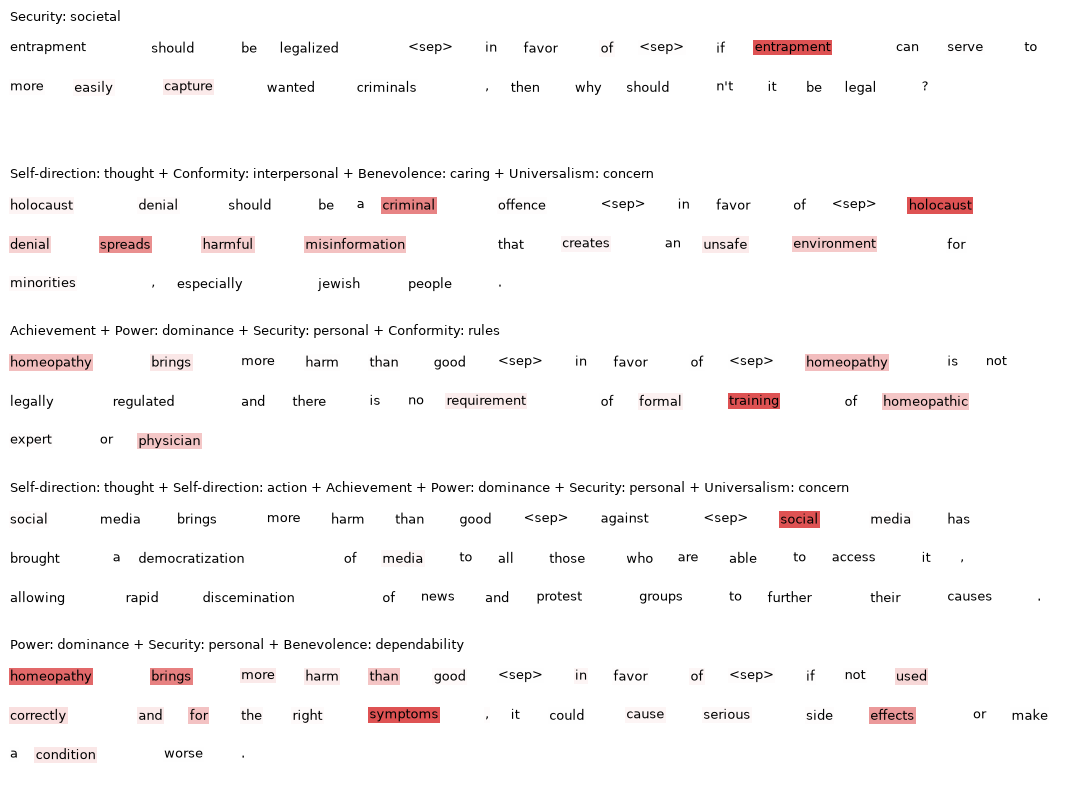

In [15]:
def afficher(ax, tokens, alpha, titre):
    m = max(alpha); x, y = 0.0, 0.9
    ax.set_axis_off(); ax.set_title(titre, fontsize=9, loc="left")
    for t, p in zip(tokens, alpha):
        if x + 0.012 * (len(t) + 1) > 1:
            x, y = 0.0, y - 0.32
        ax.text(x, y, t, fontsize=9, transform=ax.transAxes, va="top",
                bbox=dict(facecolor="tab:red", alpha=min(p / m, 1) * .8, edgecolor="none", pad=1))
        x += 0.012 * (len(t) + 1)

choix = [i for i, a in enumerate(attn) if 22 <= len(a["tokens"]) <= 42][:400:80]
fig, axes = plt.subplots(5, 1, figsize=(11, 8))
for ax, i in zip(axes, choix):
    vraies = [v for v, b in zip(VALUES, d['val'][VALUES].to_numpy()[i]) if b]
    afficher(ax, attn[i]["tokens"], attn[i]["alpha"], " + ".join(vraies))
plt.tight_layout(); plt.savefig("../figures/C2_attention.png", dpi=120); plt.show()

**Lecture (Q7) :**
- **Score :** C2 = 0,388 contre 0,420 pour C1 (une graine). L'attention rend le modèle lisible, sans le rendre meilleur ici. Hypothèse à tester : une seule distribution de poids doit servir les 20 valeurs, alors que le max-pooling choisit le mot le plus fort pour chaque dimension.
- **Conclusion :** elle reçoit 35 % de l'attention pour 21 % des tokens, soit 1,7 fois sa part : oui, l'attention se concentre sur les mots de la conclusion.
- **Position :** 1,3 % de l'attention pour 13,6 % des tokens : le modèle l'ignore presque.
- **Termes moraux :** en partie seulement. Les mots favorisés sont des **noms de domaine concrets** (pollution, climate, criminal, education, health). *health* reçoit 6 fois sa part, mais *freedom* (1,1) et *rights* (0,7) restent ordinaires.
- **Négations :** *not* et *n't* ne reçoivent presque rien (0,01). Ce poids ne prouve pas que le BiLSTM les ignore : leur information peut passer par la mémoire vers les mots suivants.

### C.5 C3 : mini-encodeur Transformer
2 couches, d_model 128, 4 têtes, encodage positionnel sinusoïdal, masque de padding. GloVe (300) est projeté en 128 dimensions.
**Ablation :** mêmes réglages sans encodage positionnel : le modèle ne connaît plus l'ordre des mots.

Comparaison sur **3 graines** (moyenne ± écart-type) : une seule graine ne suffit pas.

In [16]:
familles = {"C1 BiLSTM + max": "C1_glove_max", "C2 BiLSTM + attention": "C2_glove",
            "C3 Transformer + moyenne": "C3_glove_moyenne", "C3 sans encodage positionnel": "C3_glove_moyenne_sans_pe",
            "C4 char-CNN": "C4_charcnn"}
lignes = []
for titre, n in familles.items():
    rs = [json.loads((RUNS / f"{n}_seed{g}.json").read_text(encoding="utf-8")) for g in (42, 43, 44)]
    f = [r["macro_f1"] for r in rs]
    lignes.append({"modèle": titre, "graine 42": f[0], "graine 43": f[1], "graine 44": f[2], "moyenne": np.mean(f),
                   "écart-type": np.std(f, ddof=1), "temps moyen (s)": round(np.mean([r["temps_s"] for r in rs])),
                   "paramètres entraînés": rs[0]["params"]})
c_res = pd.DataFrame(lignes)
c_res.round(3)

,modèle,graine 42,graine 43,graine 44,moyenne,écart-type,temps moyen (s),paramètres entraînés
0,C1 BiLSTM + max,0.420,0.409,0.418,0.415,0.006,87,445460
1,C2 BiLSTM + attention,0.388,0.411,0.411,0.403,0.013,93,478484
2,C3 Transformer + moyenne,0.401,0.407,0.418,0.409,0.009,34,306068
3,C3 sans encodage positionnel,0.415,0.406,0.413,0.411,0.004,32,306068
4,C4 char-CNN,0.352,0.350,0.340,0.347,0.007,30,71572


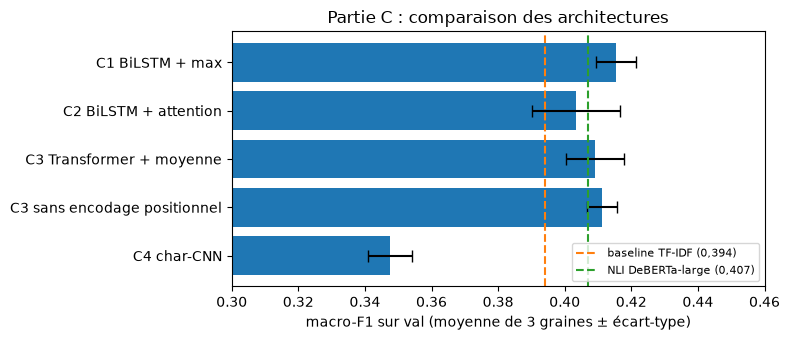

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(c_res["modèle"], c_res.moyenne, xerr=c_res["écart-type"], color="tab:blue", capsize=4)
ax.axvline(.394, color="tab:orange", ls="--", label="baseline TF-IDF (0,394)")
ax.axvline(.407, color="tab:green", ls="--", label="NLI DeBERTa-large (0,407)")
ax.invert_yaxis(); ax.set_xlim(.3, .46)
ax.set(xlabel="macro-F1 sur val (moyenne de 3 graines ± écart-type)", title="Partie C : comparaison des architectures")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.savefig("../figures/C_comparaison.png", dpi=120); plt.show()

**Lecture (Q7) :**
- **Sur 3 graines, les architectures sont très proches :** C1 0,415 ± 0,006, C3 0,409 ± 0,009, C2 0,403 ± 0,013. Les écarts sont de l'ordre de l'écart-type : on ne peut pas les classer.
- **Correction :** le 0,388 de C2 venait d'une mauvaise graine (0,411 sur les deux autres). L'explication « C2 est moins bon car une seule attention sert 20 valeurs » n'est donc pas établie.
- **Encodage positionnel :** aucun effet mesurable (0,409 avec, 0,411 sans). Sur cette tâche, savoir quels mots sont présents compte plus que leur ordre : le modèle sans positions reste au niveau des autres.
- **Coût :** C3 s'entraîne environ 2,5 fois plus vite que C1 sur nos runs (34 s contre 87 s) avec moins de paramètres.
- **Par rapport aux systèmes précédents :** ces scores sont au niveau de la baseline (0,394) et du NLI (0,407), légèrement au-dessus pour C1. Ils restent optimistes : l'époque et le seuil sont choisis sur val.

### C.6 C4 : char-CNN
Le modèle lit les **caractères** (64 symboles, 512 au maximum : 84 arguments du train sont coupés). Des filtres de 3, 5 et 7 lettres glissent sur le texte et le résumé garde la plus forte réponse de chaque filtre. Pas de GloVe.

**Lecture :** 0,347 ± 0,006, clairement en dessous des modèles sur mots (~0,41). Il n'a aucune connaissance préalable du sens des mots et n'apprend que sur 5 393 arguments, avec seulement ~72 000 paramètres. Il reste au-dessus du plancher (0,272) et proche de C1 sans GloVe (0,335).

### C.7 Déséquilibre (Q6), sur C1
- **standard** : perte normale ;
- **perte pondérée** : `pos_weight = négatifs / positifs` (calculé sur le train) ;
- **sur-échantillonnage** : tirage favorisant les arguments à valeur rare (dans le train uniquement).

Pour chacune : seuil fixe 0,5, seuil unique, et seuil par valeur. Le score « croisé » règle les seuils sur 4/5 des sujets de val et mesure sur le reste. Moyenne de 3 graines.

In [18]:
from sklearn.model_selection import GroupKFold
from valeval.data import label_matrix
from valeval.evaluate import scores, f1_par_valeur, seuil_unique, seuils_par_valeur

y_va = label_matrix(d["val"]); y_tr = label_matrix(d["train"])
groupes = d["val"].conclusion

def croise(p):
    u, v = np.zeros_like(y_va), np.zeros_like(y_va)
    for a, b in GroupKFold(5).split(p, groups=groupes):
        u[b] = p[b] >= seuil_unique(y_va[a], p[a])
        v[b] = p[b] >= seuils_par_valeur(y_va[a], p[a])
    return scores(y_va, u)["macro_f1"], scores(y_va, v)["macro_f1"]

methodes = {"standard": "C1_glove_max", "perte pondérée": "C1_perte_ponderee", "sur-échantillonnage": "C1_surechantillonnage"}
lignes, probas_m = [], {}
for titre, n in methodes.items():
    ps = [np.load(RUNS / f"{n}_seed{g}_val.npy") for g in (42, 43, 44)]
    probas_m[titre] = ps
    fixe = [scores(y_va, p >= .5)["macro_f1"] for p in ps]
    uni = [scores(y_va, p >= seuil_unique(y_va, p))["macro_f1"] for p in ps]
    cr = [croise(p) for p in ps]
    lignes.append({"méthode": titre, "seuil 0,5": np.mean(fixe), "seuil unique": np.mean(uni),
                   "croisé unique": np.mean([c[0] for c in cr]), "croisé par valeur": np.mean([c[1] for c in cr]),
                   "écart-type (croisé par valeur)": np.std([c[1] for c in cr], ddof=1)})
q6 = pd.DataFrame(lignes)
q6.round(3)

,méthode,"seuil 0,5",seuil unique,croisé unique,croisé par valeur,écart-type (croisé par valeur)
0,standard,0.298,0.415,0.414,0.418,0.005
1,perte pondérée,0.410,0.417,0.416,0.415,0.003
2,sur-échantillonnage,0.336,0.406,0.404,0.405,0.006


In [19]:
def f1_moyen(ps):
    return pd.DataFrame([f1_par_valeur(y_va, p >= seuils_par_valeur(y_va, p)) for p in ps]).mean()

parv = pd.DataFrame({t: f1_moyen(ps) for t, ps in probas_m.items()})
parv.insert(0, "n_train", pd.Series(dict(zip(VALUES, y_tr.sum(0)))))
parv.sort_values("n_train").round(3)

,n_train,standard,perte pondérée,sur-échantillonnage
Hedonism,172,0.339,0.324,0.361
Conformity: interpersonal,207,0.215,0.250,0.245
Stimulation,247,0.303,0.281,0.271
Face,382,0.265,0.295,0.265
Humility,395,0.160,0.189,0.155
Universalism: nature,427,0.663,0.677,0.645
Tradition,568,0.416,0.439,0.420
Power: dominance,610,0.322,0.316,0.275
Power: resources,625,0.481,0.494,0.469
Universalism: tolerance,664,0.279,0.269,0.278


**Lecture (Q6) :**
- **Le seuil fait l'essentiel :** le modèle standard passe de 0,298 (seuil 0,5) à 0,414 (seuil réglé, score croisé), sans rien changer à l'entraînement.
- **Perte pondérée :** à 0,5, elle atteint 0,410, car elle décale les probabilités vers le haut. Une fois le seuil réglé, elle ne fait pas mieux que le standard (0,416 contre 0,414).
- **Sur-échantillonnage :** légèrement moins bon (0,404 contre 0,414 en croisé).
- **Seuil par valeur :** gain nul à faible (0,414 → 0,418 pour le standard), de l'ordre de l'écart-type.
- **Valeurs à F1 faible :** *Humility* (~0,16, 395 exemples), *Conformity: interpersonal* (~0,22, 207), *Face* (~0,27, 382), *Universalism: tolerance* (~0,28, 664), *Benevolence: dependability* (~0,31, 806). Le tableau par valeur règle ses seuils sur les mêmes données : ces F1 sont légèrement optimistes.
- *Universalism: nature* atteint ~0,66 avec 427 exemples : le nombre d'exemples n'explique pas tout.

**Décision :** C1 standard + seuil unique, la solution la plus simple à score équivalent.

**Pourquoi le sur-échantillonnage après la séparation train / val ?** Sinon, des copies d'un même argument se retrouvent des deux côtés : le modèle est évalué sur des exemples déjà vus et le score val est gonflé.

### C.8 Ablations de prétraitement (Q3)
On réentraîne C1 (GloVe, max-pooling) en retirant une famille de tokens du train **et** de val, sur 3 graines. Les « mots moraux » sont ceux de `value-categories.json`.
La casse se mesure sur la baseline TF-IDF : GloVe ne contient que des minuscules.

In [20]:
abl = {"référence": "C1_glove_max", "sans négations": "C1_sans_negations", "sans mots vides": "C1_sans_mots_vides",
       "sans ponctuation": "C1_sans_ponctuation", "sans mots moraux": "C1_sans_mots_moraux"}
lignes = []
for titre, n in abl.items():
    f = [json.loads((RUNS / f"{n}_seed{g}.json").read_text(encoding="utf-8"))["macro_f1"] for g in (42, 43, 44)]
    lignes.append({"variante": titre, "graine 42": f[0], "graine 43": f[1], "graine 44": f[2],
                   "moyenne": np.mean(f), "écart-type": np.std(f, ddof=1)})
q3 = pd.DataFrame(lignes)
q3["écart à la référence"] = q3.moyenne - q3.moyenne[0]
print("Casse (baseline TF-IDF, val) :", json.loads((RUNS / "tfidf_casse.json").read_text(encoding="utf-8")))
q3.round(3)

Casse (baseline TF-IDF, val) : {'minuscules': 0.3941142446636842, 'casse conservée': 0.39081667384073493}


,variante,graine 42,graine 43,graine 44,moyenne,écart-type,écart à la référence
0,référence,0.420,0.409,0.418,0.415,0.006,0.000
1,sans négations,0.424,0.417,0.418,0.420,0.004,0.004
2,sans mots vides,0.412,0.410,0.415,0.412,0.003,-0.003
3,sans ponctuation,0.417,0.428,0.420,0.422,0.006,0.006
4,sans mots moraux,0.409,0.412,0.405,0.409,0.003,-0.007


**Lecture (Q3) :**
- **Aucune ablation n'a d'effet net.** Tous les écarts à la référence (0,415) sont faibles : de -0,007 à +0,006, pour des écarts-types de 0,003 à 0,006.
- **Négations :** les retirer ne fait pas baisser le score (+0,004). Ce modèle ne semble pas en dépendre.
- **Mots moraux :** c'est la seule ablation dont l'écart dépasse l'écart-type à la baisse (-0,007), ce qui reste petit : la valeur est rarement nommée dans le texte.
- **Mots vides et ponctuation :** -0,003 et +0,006, sans effet établi.
- **Casse (baseline TF-IDF) :** 0,394 en minuscules contre 0,391 en casse conservée : pas d'effet utile.

**Par famille de modèles :**
| Famille | Prétraitement | Pourquoi |
|---|---|---|
| Baseline TF-IDF | minuscules | la casse n'aide pas |
| Réseaux sur mots | minuscules, contractions coupées comme GloVe, rien de retiré | GloVe est en minuscules ; aucune ablation ne justifie un retrait |
| Char-CNN | minuscules | même choix |
| NLI et PLM | texte brut | leur tokenizer est prévu pour le texte d'origine |

**Décision :** on garde la référence. Retirer ponctuation ou négations afficherait un score un peu plus haut, mais l'écart est dans le bruit, et choisir le meilleur des cinq sur val serait de la sur-sélection.